# Chapter 07: Stage 5A — Natural Language Processing (NLP), Tokenization, TF-IDF & Sentiment/Spam Classification

**Assalam-o-Alaikum!** Ab hum **Stage 5: Natural Language Processing (NLP)** shuru kar rahe hain — yani AI ko insani zubaan (English / Roman Urdu reviews, emails, messages) samajhna sikhana!

### 1. Text Ko Numbers Mein Kaise Badalte Hain? (`Tokenization` $ightarrow$ `TF-IDF`)
Machine Learning models sirf numbers samajhte hain. Text ko numbers mein badalne ke 3 steps hain:
1. **Text Preprocessing:** Lowercase karna (`"Great!"` $ightarrow$ `"great"`), punctuation hatana.
2. **Tokenization:** Jumle ko lafzon (**Tokens**) mein torna: `["great", "phone", "battery"]`.
3. **TF-IDF (`Term Frequency - Inverse Document Frequency`):** Har lafz ko ek weight dena — jo lafz kisi review mein khaas ho (`"excellent"`, `"terrible"`) usay zyada weight milta hai, aur aam lafzon (`"the"`, `"is"`) ko kam!

In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

### Step 1 — Load `reviews_sentiment.xlsx` Dataset

In [2]:
database = pd.read_excel("datasets/reviews_sentiment.xlsx")
database.head(6)

,review_id,review_text,sentiment
0,1,Excellent quality product fast delivery highly recommended (Order #100),1
1,2,Terrible quality broke on first day waste of money (Order #200),0
2,3,Amazing phone camera battery life is super great value (Order #101),1
3,4,Very slow delivery rude staff and damaged box (Order #201),0
4,5,Very happy with the service friendly staff and clean rooms (Order #102),1
5,6,Worst battery life phone gets hot and crashes (Order #202),0


### Step 2 — Build `TfidfVectorizer` + `LogisticRegression` & `MultinomialNB` Pipelines

In [3]:
x = database["review_text"]
y = database["sentiment"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

nb_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2))),
    ("nb", MultinomialNB()),
])
nb_pipe.fit(x_train, y_train)

lr_nlp_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2))),
    ("clf", LogisticRegression()),
])
lr_nlp_pipe.fit(x_train, y_train)

print("MultinomialNB Test Accuracy (%):", round(nb_pipe.score(x_test, y_test) * 100, 2))
print("LogisticReg   Test Accuracy (%):", round(lr_nlp_pipe.score(x_test, y_test) * 100, 2))

MultinomialNB Test Accuracy (%): 100.0
LogisticReg   Test Accuracy (%): 100.0


### Step 3 — Save NLP Pipeline & Predict Sentiment on Brand-New Customer Reviews

In [4]:
joblib.dump(lr_nlp_pipe, "models/sentiment_tfidf_pipeline.pkl")

new_reviews = [
    "Amazing phone camera and super fast delivery highly recommended",
    "Worst battery life broke on first day waste of money",
]
preds = lr_nlp_pipe.predict(new_reviews)
probs = lr_nlp_pipe.predict_proba(new_reviews)[:, 1]

for rev, p, pr in zip(new_reviews, preds, probs):
    label = "POSITIVE (1)" if p == 1 else "NEGATIVE (0)"
    print(f"Review: {rev} -> Predicted: {label} ({pr*100:.1f}%)")

Review: Amazing phone camera and super fast delivery highly recommended -> Predicted: POSITIVE (1) (99.1%)
Review: Worst battery life broke on first day waste of money -> Predicted: NEGATIVE (0) (0.5%)


### Step 4 — Inspect Dataset (`database.shape`, `database.isnull().sum()`, Class Counts)

In [5]:
database.shape, database["sentiment"].value_counts().to_dict()

((80, 3), {1: 40, 0: 40})

### Step 5 — Inspect Learned Vocabulary & Top TF-IDF Features
Chalein dekhte hain ke `TfidfVectorizer` ne reviews mein se kaun-kaun se ahem الفاظ (`vocabulary_`) seekhe:

In [6]:
tfidf_step = lr_nlp_pipe.named_steps["tfidf"]
clf_step = lr_nlp_pipe.named_steps["clf"]
feature_names = tfidf_step.get_feature_names_out()
coefs = clf_step.coef_[0]

top_pos_idx = np.argsort(coefs)[-5:][::-1]
top_neg_idx = np.argsort(coefs)[:5]
print("Top 5 Positive Words:", [(feature_names[i], round(coefs[i], 2)) for i in top_pos_idx])
print("Top 5 Negative Words:", [(feature_names[i], round(coefs[i], 2)) for i in top_neg_idx])

Top 5 Positive Words: [(np.str_('order'), np.float64(6.92)), (np.str_('great'), np.float64(2.43)), (np.str_('super'), np.float64(2.0)), (np.str_('fast'), np.float64(1.92)), (np.str_('happy_service'), np.float64(1.77))]
Top 5 Negative Words: [(np.str_('broken_order'), np.float64(-1.81)), (np.str_('bad_experience'), np.float64(-1.81)), (np.str_('scratched_broken'), np.float64(-1.81)), (np.str_('experience_screen'), np.float64(-1.81)), (np.str_('screen_scratched'), np.float64(-1.81))]


### Step 6 — Plot Sentiment Confusion Matrix Heatmap

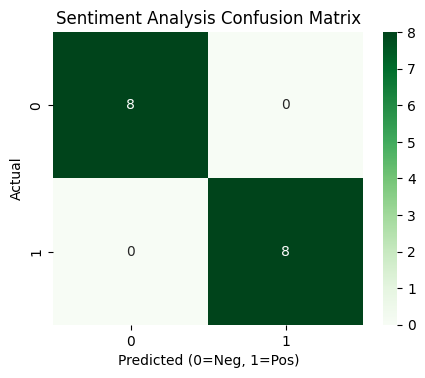

In [7]:
y_pred_nlp = lr_nlp_pipe.predict(x_test)
cm_nlp = confusion_matrix(y_test, y_pred_nlp)
plt.figure(figsize=(5, 3.8))
sns.heatmap(cm_nlp, annot=True, fmt="d", cmap="Greens")
plt.title("Sentiment Analysis Confusion Matrix")
plt.xlabel("Predicted (0=Neg, 1=Pos)")
plt.ylabel("Actual")
plt.show()

### Step 7 — Error Analysis on Tricky/Sarcastic Sentences & Practical Exercise
**Limitation of TF-IDF:** Agar kisi review mein sarcastic jumla ho jaise *"Great, the phone broke in 5 minutes!"*, toh `TF-IDF` lafz `"Great"` dekh kar dhoka kha sakta hai. Is masle ko Stage 5B (**Transformers & Self-Attention**) hal karta hai!

In [8]:
# Practical Exercise: Test custom reviews on the saved sentiment pipeline
loaded_nlp = joblib.load("models/sentiment_tfidf_pipeline.pkl")
test_sentences = [
    "Loved the course clear explanation and practical examples",
    "Useless charger does not work at all refund needed",
]
for s, p in zip(test_sentences, loaded_nlp.predict(test_sentences)):
    print(f"'{s}' -> Sentiment: {'POSITIVE (1)' if p==1 else 'NEGATIVE (0)'}")

'Loved the course clear explanation and practical examples' -> Sentiment: POSITIVE (1)
'Useless charger does not work at all refund needed' -> Sentiment: NEGATIVE (0)


### Chapter 07 Revision Quiz
1. **`TfidfVectorizer` ko sirf `x_train` par fit kyun karte hain?** Taake test set ke unseen words vocabulary mein leak na hon.
2. **`ngram_range=(1, 2)` ka kya faida hai?** Yeh single words (`"good"`) ke saath 2-word phrases (`"not_good"`, `"fast_delivery"`) bhi pakarta hai.